In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sottools.forward as forward
import sottools.mesh as mesh
from sottools import backward

params = forward.Forward2DParameters(
    Lx = 6.0,
    Ly = 8.0,
    Nx = 192,
    Ny = 256, # Take care: pixels must be PERFECTLY square
    rho1 = 0.02,
    rho2 = 0.05,
    height = 0.05,
    phi = np.deg2rad(63.0), # Standard TM-SOT sensor tilt angle
    invert_normal=True # Sets the sign of the SQUID response
)
fwd = forward.Forward2DCurrent(params)

In [2]:
vertices = [
    [ 0.0, -5.0],
    [-0.5, -5.0],
    [-0.5,  5.0],
    [ 0.0,  5.0],
    [ 0.0,  0.15],
    [ 0.05,  0.15],
    [ 0.05,  1.2],
    [ 2.0,  1.2],
    [ 2.0, -1.2],
    [ 0.05, -1.2],
    [ 0.05, -0.3],
    [ 0.0, -0.3],
]
segments = [
    [0, 1],
    [1, 2],
    [2, 3],
    [3, 4],
    [4, 5],
    [5, 6],
    [6, 7],
    [7, 8],
    [8, 9],
    [9, 10],
    [10, 11],
    [11, 0]
]
BM = mesh.SimplyConnectedCurrentMesh.BoundaryMarker
segment_markers = [
    BM.NEUMANN_IN,
    BM.DIRICHLET_RIGHT,
    BM.NEUMANN_OUT,
    BM.DIRICHLET_LEFT,
    BM.DIRICHLET_LEFT,
    BM.DIRICHLET_LEFT,
    BM.DIRICHLET_LEFT,
    BM.DIRICHLET_LEFT,
    BM.DIRICHLET_LEFT,
    BM.DIRICHLET_LEFT,
    BM.DIRICHLET_LEFT,
    BM.DIRICHLET_LEFT,
]

constrictionmesh = mesh.SimplyConnectedCurrentMesh(
    vertices,
    segments,
    segment_markers,
    max_area = 2e-4,
    refine_distance = 0.02
)

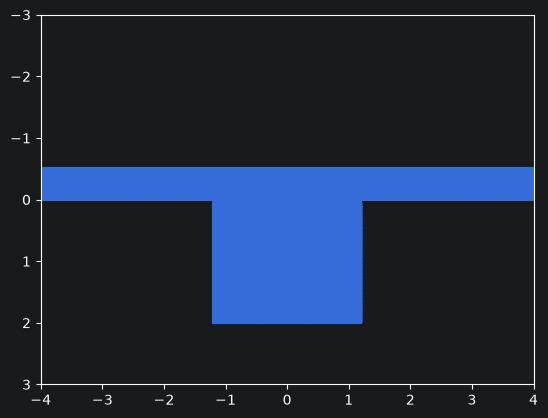

In [3]:
import sottools.utils.meshplotting as meshplotting

fig, ax = plt.subplots(1,1)
meshplotting.plot_mesh(constrictionmesh, ax)
ax.set_xlim(-4, 4)
ax.set_ylim(3, -3)
plt.show()

In [4]:
tau = 1e-12 # 1 ps, momentum relaxation
q = 1.602e-13 # Elementary charge in uA·s
density = 1e4 # 10^4 electrons per square micron
ten = tau/(q*density)
viscosity = 1e11#1e11 # um^2/s -> 0.1 m^2/s
D = np.sqrt(tau*viscosity) # Gurzi length

solver = mesh.HydroSolver(
    constrictionmesh,
    ten,
    D,
    verbose=True
)

res = solver.solve(left_bc = 0.0, right_bc = 1.0)

Iter 0: relative change in g: 2.37e-01, relative change in omega: 2.50e-01
Iter 1: relative change in g: 4.02e-02, relative change in omega: 4.17e-02
Iter 2: relative change in g: 7.79e-03, relative change in omega: 8.06e-03
Iter 3: relative change in g: 1.55e-03, relative change in omega: 1.60e-03
Iter 4: relative change in g: 3.09e-04, relative change in omega: 3.20e-04
Iter 5: relative change in g: 6.18e-05, relative change in omega: 6.40e-05
Iter 6: relative change in g: 1.24e-05, relative change in omega: 1.28e-05
Iter 7: relative change in g: 2.47e-06, relative change in omega: 2.56e-06
Converged after 8 iterations


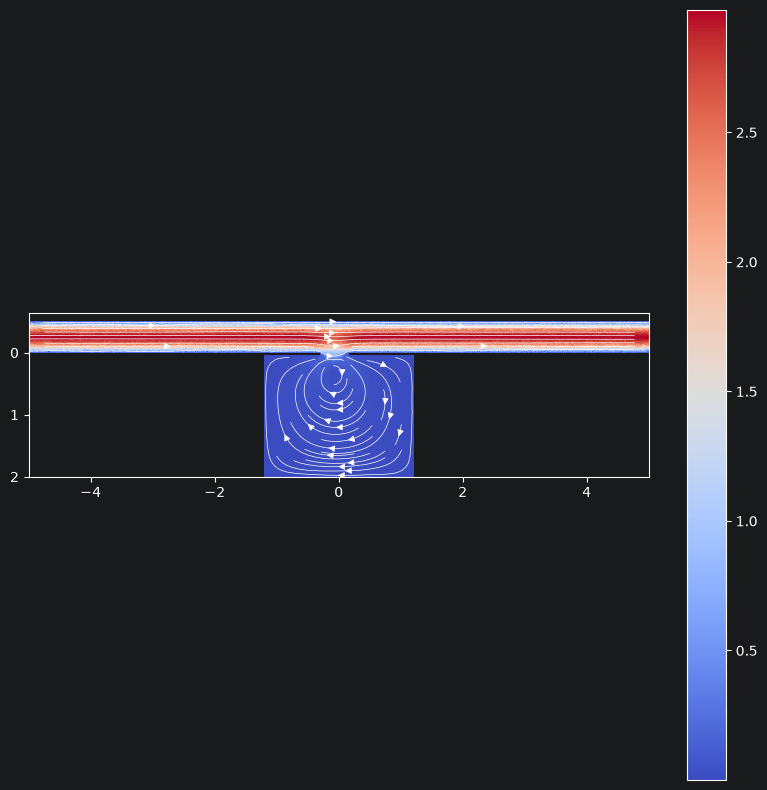

In [5]:
fig, ax = plt.subplots(1,1, figsize = (10,10))
meshplotting.streamplot(constrictionmesh, ax, res["Kx"], res["Ky"], n_grid=256, density=1.5, cmap='coolwarm')
plt.show()

C:\Users\LION\sottools\src\sottools\forward.py:1215: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:823.)
  torch.sparse_coo_tensor(


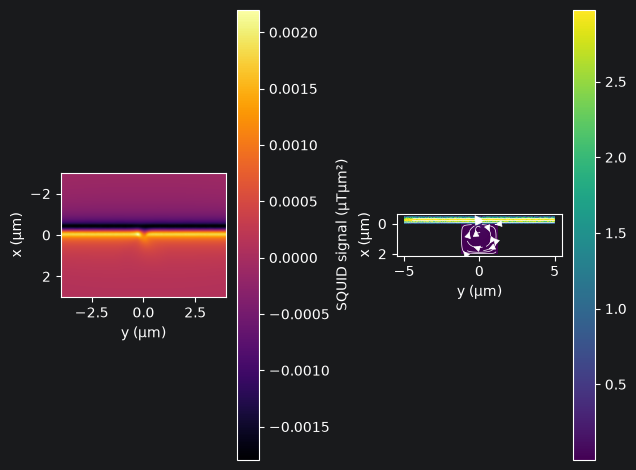

In [6]:
m2g = forward.MeshToGrid(constrictionmesh, params)
signal = fwd.forward(*m2g.streamfunction_to_currents(res["streamfunction"]))

fig, (ax0, ax1) = plt.subplots(1, 2)
im0 = ax0.imshow(signal, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2], cmap='inferno')
ax0.set_xlabel('y (µm)')
ax0.set_ylabel('x (µm)')
ax0.set_aspect('equal')
meshplotting._streamplot(constrictionmesh, ax1, res["Kx"], res["Ky"], n_grid=256)
ax1.set_xlabel('y (µm)')
ax1.set_ylabel('x (µm)')
plt.colorbar(im0, ax=ax0, label='SQUID signal (µTµm²)')
plt.tight_layout()
plt.show()


In [7]:
import torch

# --- 1. Ohmic flow carrying 1 uA: Laplace problem with g = 0 (left wall), g = 1 (right wall)
K = constrictionmesh.stiffness_matrix
free_idx = constrictionmesh.free_idx
dir_idx = constrictionmesh.dirichlet_idx

g1 = np.zeros(constrictionmesh.vertices.shape[0])
g1[constrictionmesh.dirichletright_mask] = 1.0
g1[free_idx] = constrictionmesh.stiffness_matrix_solver.solve(
    -K[free_idx][:, dir_idx] @ g1[dir_idx]
)

# --- 2. Best-fitting amplitude: the forward model is linear, so least squares is closed form
S1 = fwd.forward(*m2g.streamfunction_to_currents(g1))
a = np.sum(S1 * signal) / np.sum(S1 * S1)
print(f"Ohmic warm start: total current a = {a:.4f} uA")
print(f"mean(signal^2)              = {np.mean(signal**2):.3e}  (fidelity of a zero start)")
print(f"mean((signal - a*S1)^2)     = {np.mean((signal - a * S1)**2):.3e}  (fidelity of the warm start)")

# --- 3. Build the inverter and overwrite its zero initial guess with a * g1
inverter = backward.Inverter2D(
    m2g,
    fwd,
    signal,
    lam1=1e-11,
    lam2=1e-10,
    lumped_mass=True,
)
# Parameter layout of Inverter2D: solution[0] = right-wall value, solution[1:] = free nodes
# (in increasing node order, matching free_idx); the left wall is fixed at 0.
with torch.no_grad():
    inverter._solution[0] =  float(a)
    inverter._solution[1:] = torch.from_numpy(a * g1[free_idx]).to(inverter._solution.dtype)

inversionresult = inverter.fit(
    lr=3e-4, n_steps=500, callback=backward.PrintCallback1D(), callback_every=1
)

Ohmic warm start: total current a = 1.0125 uA
mean(signal^2)              = 3.345e-07  (fidelity of a zero start)
mean((signal - a*S1)^2)     = 2.594e-08  (fidelity of the warm start)
[█████████████████████████████░]   499/500  loss=2.353e-08  fid=1.942e-08  reg=4.109e-09


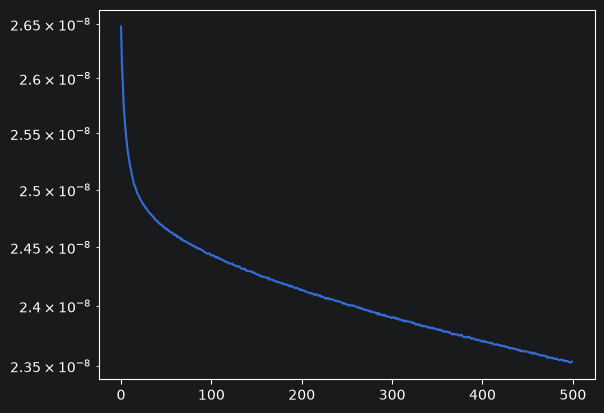

In [8]:
plt.semilogy(inversionresult["loss_history"])

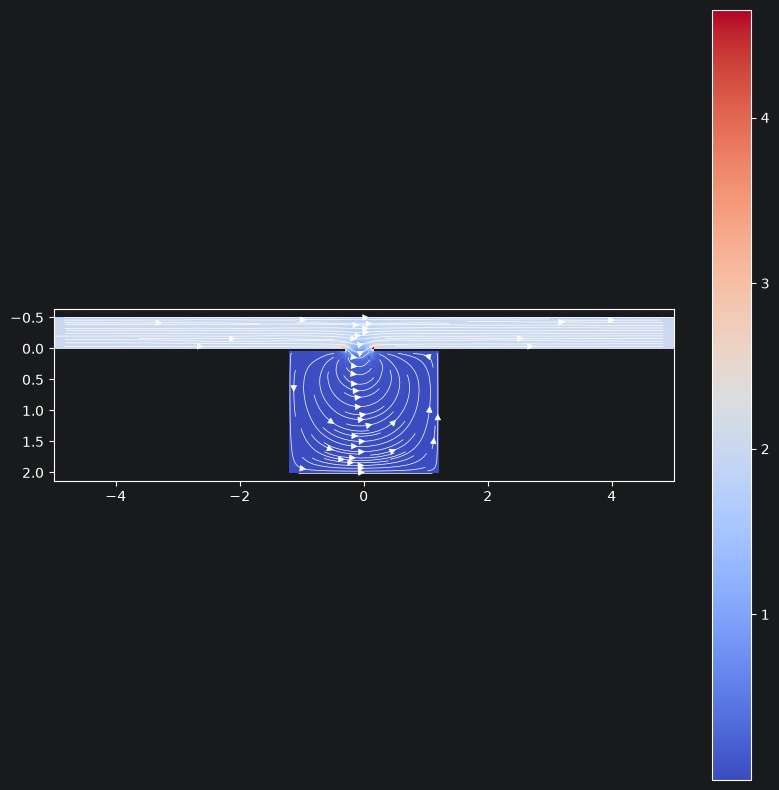

In [9]:
fig, ax = plt.subplots(1,1, figsize = (10,10))
meshplotting.streamplot(constrictionmesh, ax, inversionresult["Kx"], inversionresult["Ky"], n_grid=256, density=2.0, cmap='coolwarm')
plt.show()

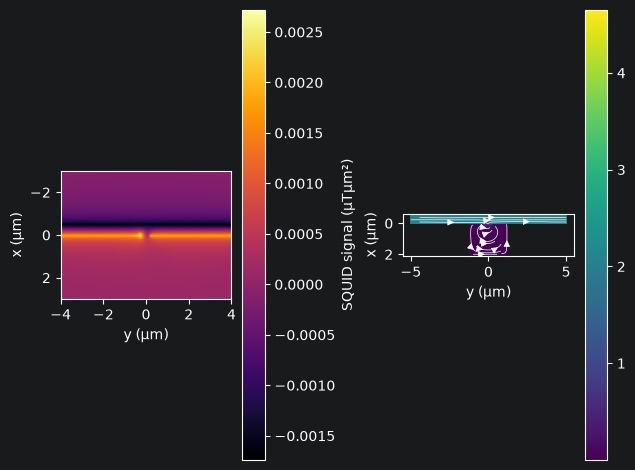

In [10]:
predsignal = fwd.forward(*m2g.streamfunction_to_currents(inversionresult["streamfunction"]))

fig, (ax0, ax1) = plt.subplots(1, 2)
im0 = ax0.imshow(predsignal, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2], cmap='inferno')
ax0.set_xlabel('y (µm)')
ax0.set_ylabel('x (µm)')
ax0.set_aspect('equal')
meshplotting._streamplot(constrictionmesh, ax1, inversionresult["Kx"], inversionresult["Ky"], n_grid=256)
ax1.set_xlabel('y (µm)')
ax1.set_ylabel('x (µm)')
plt.colorbar(im0, ax=ax0, label='SQUID signal (µTµm²)')
plt.tight_layout()
plt.show()


lam1 = 1.0e-11, lam2 = 1.0e-10
                    fid   lam1*Tik    lam2*TV      total
truth         0.000e+00  8.951e-09  8.374e-09  1.733e-08
fit           1.942e-08  1.212e-09  2.895e-09  2.353e-08
warm start    2.594e-08  1.108e-11  5.278e-10  2.648e-08

rms(signal)     = 5.784e-04
rms(correction) = 1.611e-04  (hydro part beyond ohmic)
rms(residual)   = 1.394e-04  (left unexplained by the fit)


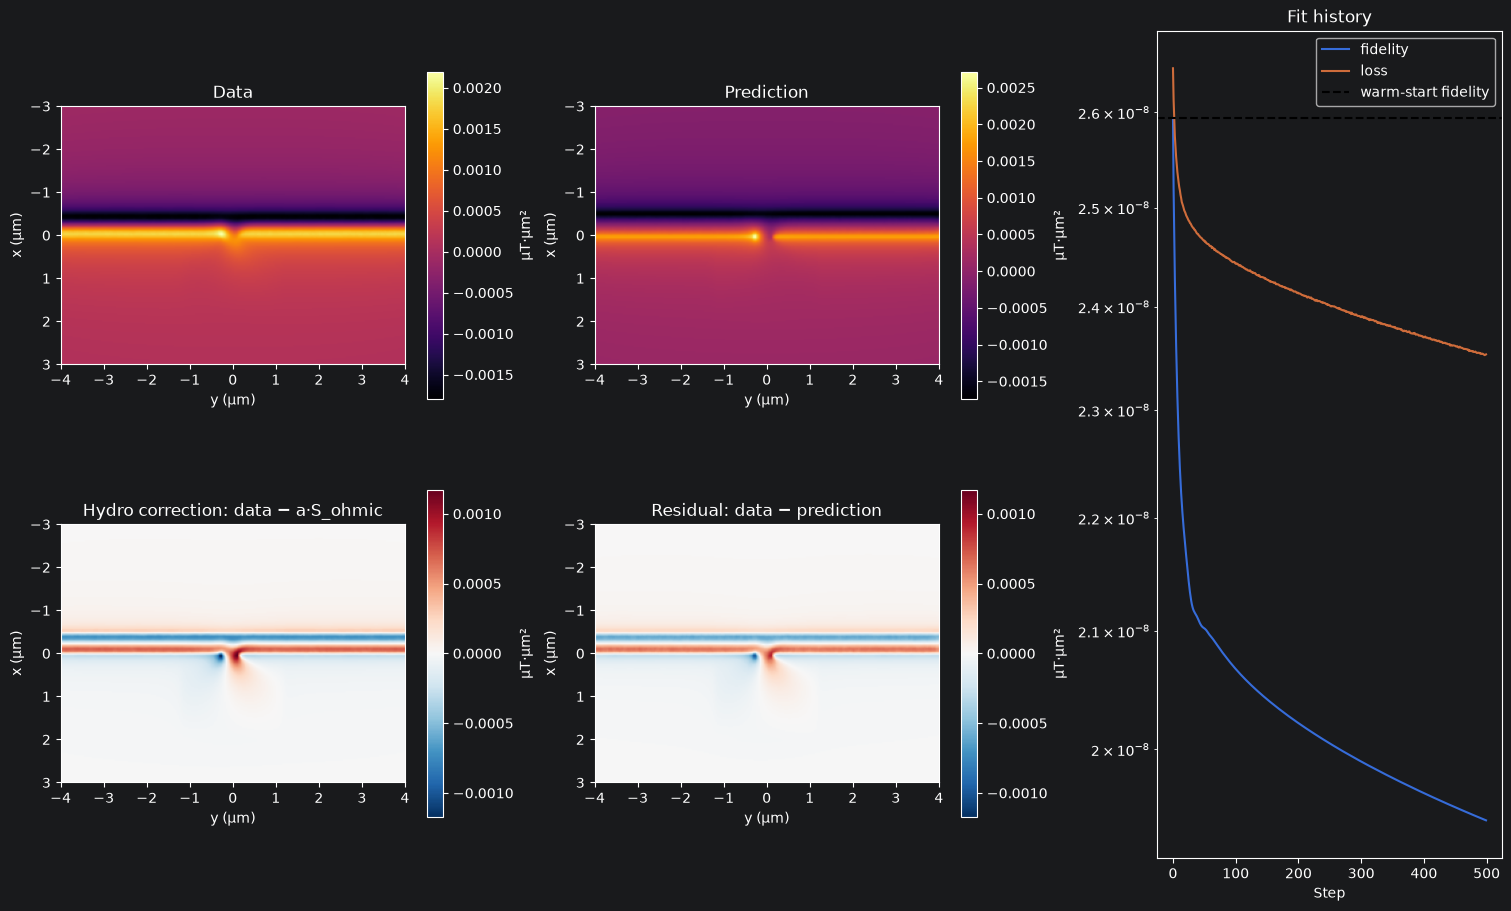

In [11]:
import torch

mesh_ = constrictionmesh
free_idx = mesh_.free_idx
dir_idx = mesh_.dirichlet_idx
extent = [-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2]

# ---------------------------------------------------------------------------
# 1. Objective terms at the true solution and at the fit
# ---------------------------------------------------------------------------
def objective_terms(inverter, g):
    """Fidelity, lam1*Tikhonov, lam2*TV of a full streamfunction g (N_v,)."""
    saved = inverter._solution.detach().clone()
    with torch.no_grad():
        inverter._solution[0] = float(g[mesh_.dirichletright_mask][0])
        inverter._solution[1:] = torch.from_numpy(g[free_idx]).to(inverter._solution.dtype)
        _, fid, tik, tv = inverter._objective(inverter._solution)
        inverter._solution.copy_(saved)
    return fid.item(), inverter.lam1 * tik.item(), inverter.lam2 * tv.item()

# Ohmic warm start, recomputed so this cell is self-contained
K = mesh_.stiffness_matrix
g1 = np.zeros(mesh_.vertices.shape[0])
g1[mesh_.dirichletright_mask] = 1.0
g1[free_idx] = mesh_.stiffness_matrix_solver.solve(-K[free_idx][:, dir_idx] @ g1[dir_idx])
S1 = fwd.forward(*m2g.streamfunction_to_currents(g1))
a = float(np.sum(S1 * signal) / np.sum(S1 * S1))

print(f"lam1 = {inverter.lam1:.1e}, lam2 = {inverter.lam2:.1e}")
print(f"{'':12s} {'fid':>10s} {'lam1*Tik':>10s} {'lam2*TV':>10s} {'total':>10s}")
for label, g in [
    ("truth", res["streamfunction"]),
    ("fit", inversionresult["streamfunction"]),
    ("warm start", a * g1),
]:
    fid, tik, tv = objective_terms(inverter, g)
    print(f"{label:12s} {fid:10.3e} {tik:10.3e} {tv:10.3e} {fid + tik + tv:10.3e}")

# ---------------------------------------------------------------------------
# 2. Signals: data, prediction, residual, and the hydrodynamic correction
# ---------------------------------------------------------------------------
predsignal = fwd.forward(*m2g.streamfunction_to_currents(inversionresult["streamfunction"]))
residual = signal - predsignal
correction = signal - a * S1   # what the fit must explain beyond ohmic flow
print(f"\nrms(signal)     = {np.sqrt(np.mean(signal**2)):.3e}")
print(f"rms(correction) = {np.sqrt(np.mean(correction**2)):.3e}  (hydro part beyond ohmic)")
print(f"rms(residual)   = {np.sqrt(np.mean(residual**2)):.3e}  (left unexplained by the fit)")

fig = plt.figure(figsize=(15, 9), layout="constrained")
gs = fig.add_gridspec(2, 3)
panels = [
    (gs[0, 0], signal, "Data", None),
    (gs[0, 1], predsignal, "Prediction", None),
    (gs[1, 0], correction, "Hydro correction: data − a·S_ohmic", "sym"),
    (gs[1, 1], residual, "Residual: data − prediction", "sym"),
]
vsym = np.abs(correction).max()   # same colour scale for correction and residual
for spec, img, title, mode in panels:
    ax = fig.add_subplot(spec)
    if mode == "sym":
        im = ax.imshow(img, extent=extent, cmap="RdBu_r", vmin=-vsym, vmax=vsym)
    else:
        im = ax.imshow(img, extent=extent, cmap="inferno")
    ax.set_title(title)
    ax.set_xlabel("y (µm)")
    ax.set_ylabel("x (µm)")
    fig.colorbar(im, ax=ax, shrink=0.8, label="µT·µm²")

ax = fig.add_subplot(gs[:, 2])
ax.semilogy(inversionresult["fidelity_history"], label="fidelity")
ax.semilogy(inversionresult["loss_history"], label="loss")
ax.axhline(np.mean(correction**2), color="k", ls="--", label="warm-start fidelity")
ax.set_xlabel("Step")
ax.set_title("Fit history")
ax.legend()
plt.show()

fine mesh: 38721 nodes, coarse mesh: 2201 nodes
outer 0:   207 evals, loss = 4.565e-08, fid = 2.383e-08  (2 s)
outer 1:   411 evals, loss = 3.806e-08, fid = 2.421e-08  (5 s)
outer 2:   615 evals, loss = 3.737e-08, fid = 2.413e-08  (7 s)
outer 3:   823 evals, loss = 3.702e-08, fid = 2.411e-08  (10 s)
outer 4:   881 evals, loss = 3.702e-08, fid = 2.411e-08  (10 s)
outer 5:   886 evals, loss = 3.702e-08, fid = 2.411e-08  (11 s)
outer 6:   891 evals, loss = 3.702e-08, fid = 2.411e-08  (11 s)
outer 7:   896 evals, loss = 3.702e-08, fid = 2.411e-08  (11 s)
outer 8:   901 evals, loss = 3.702e-08, fid = 2.411e-08  (11 s)
outer 9:   906 evals, loss = 3.702e-08, fid = 2.411e-08  (11 s)

rms(residual coarse L-BFGS) = 1.553e-04   (fine-mesh Adam/L-BFGS: ~1.0e-04)
circulating current: truth 0.0335 uA, coarse fit 0.0005 uA, fine L-BFGS 0.0384 uA


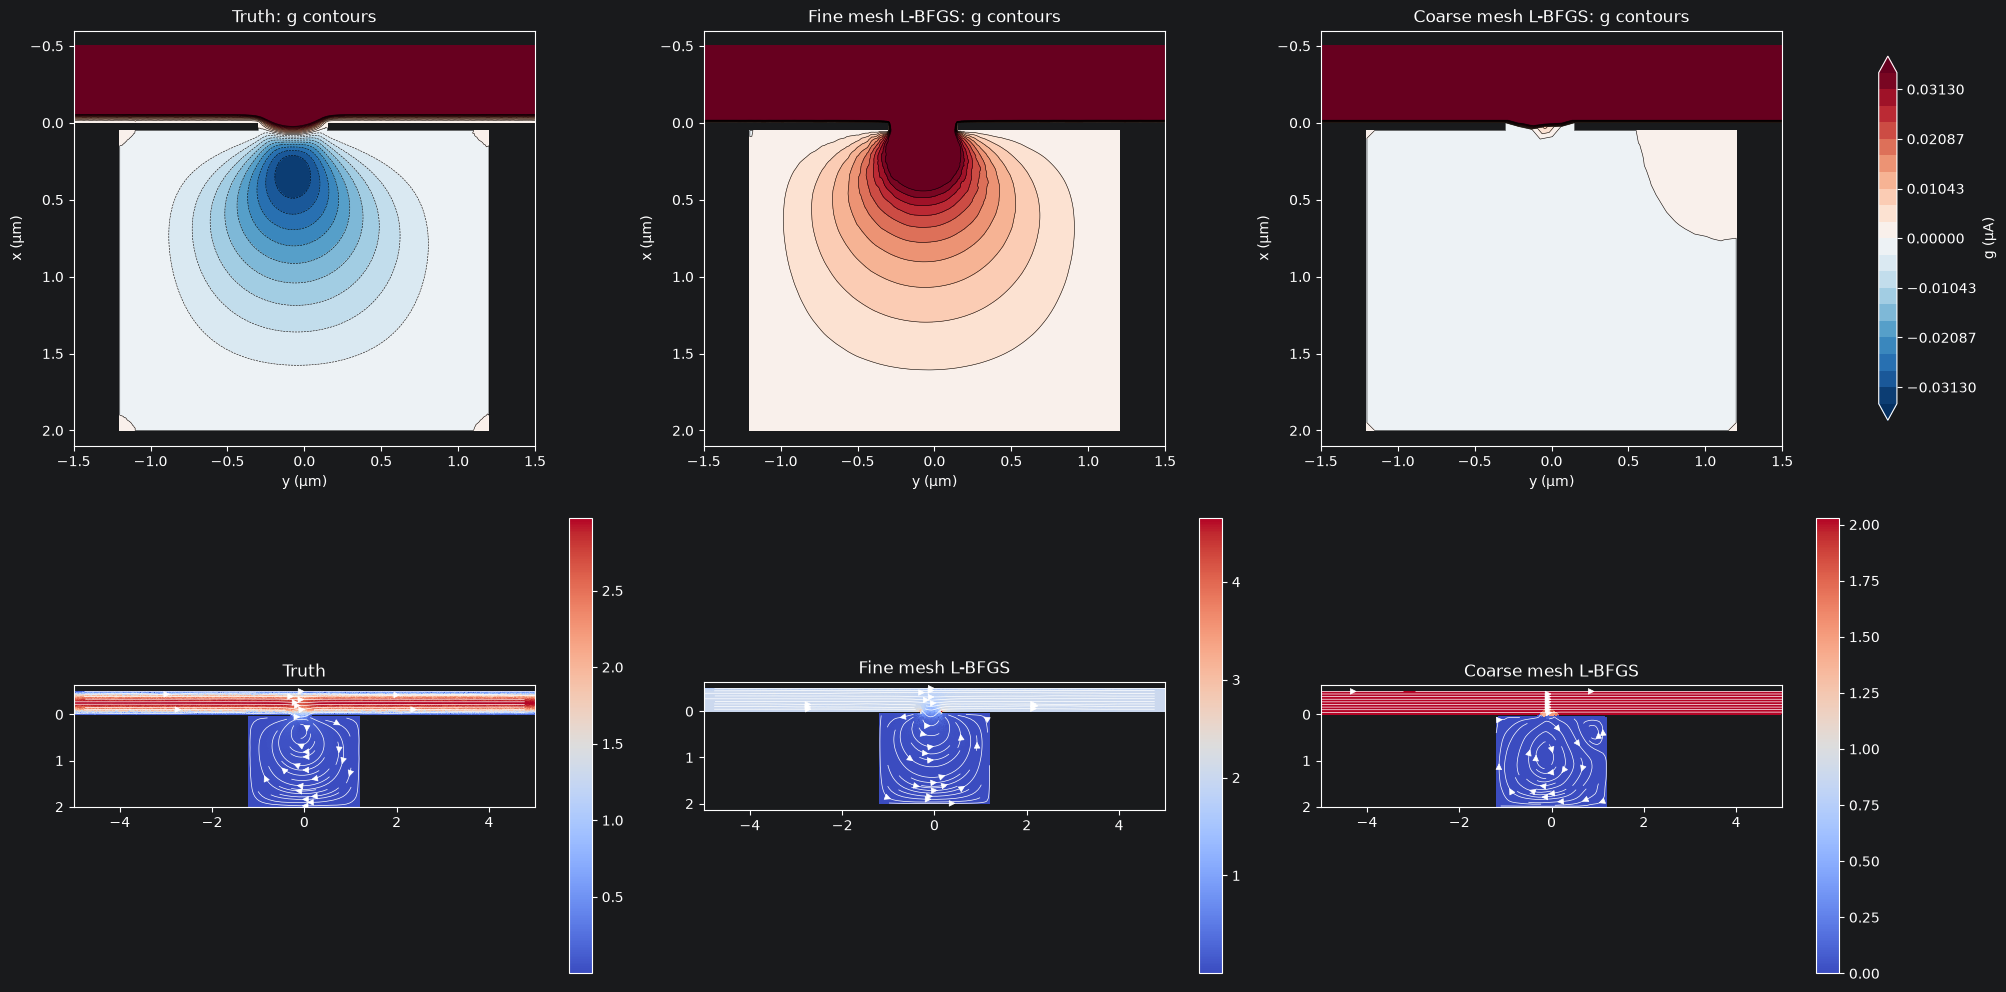

In [12]:
import time
import torch
import matplotlib.tri as mtri

# ---------------------------------------------------------------------------
# 1. Coarse reconstruction mesh: same polygon, h ~ 0.1 um
# ---------------------------------------------------------------------------
coarsemesh = mesh.SimplyConnectedCurrentMesh(
    vertices, segments, segment_markers, max_area=5e-3, refine_distance=0.05
)
m2g_c = forward.MeshToGrid(coarsemesh, params)
print(f"fine mesh: {constrictionmesh.vertices.shape[0]} nodes, "
      f"coarse mesh: {coarsemesh.vertices.shape[0]} nodes")

# ---------------------------------------------------------------------------
# 2. Inverter on the coarse mesh with the ohmic warm start
# ---------------------------------------------------------------------------
fi, di = coarsemesh.free_idx, coarsemesh.dirichlet_idx
Kc = coarsemesh.stiffness_matrix
g1c = np.zeros(coarsemesh.vertices.shape[0])
g1c[coarsemesh.dirichletright_mask] = 1.0
g1c[fi] = coarsemesh.stiffness_matrix_solver.solve(-Kc[fi][:, di] @ g1c[di])
S1c = fwd.forward(*m2g_c.streamfunction_to_currents(g1c))
ac = float(np.sum(S1c * signal) / np.sum(S1c * S1c))

inv_c = backward.Inverter2D(
    m2g_c, fwd, signal, lam1=inverter.lam1, lam2=1e-8, lumped_mass=True
)
with torch.no_grad():
    inv_c._solution[0] = ac
    inv_c._solution[1:] = torch.from_numpy(ac * g1c[fi]).to(inv_c._solution.dtype)

# ---------------------------------------------------------------------------
# 3. L-BFGS
# ---------------------------------------------------------------------------
scale = float(np.mean(signal**2))
opt = torch.optim.LBFGS(
    [inv_c._solution], lr=1.0, max_iter=200, history_size=50,
    tolerance_grad=1e-12, tolerance_change=1e-14, line_search_fn="strong_wolfe",
)
hist = []

def closure():
    opt.zero_grad()
    loss, fid, tik, tv = inv_c._objective(inv_c._solution)
    (loss / scale).backward()
    hist.append((loss.item(), fid.item()))
    return loss / scale

t0 = time.time()
for outer in range(10):
    opt.step(closure)
    print(f"outer {outer}: {len(hist):5d} evals, loss = {hist[-1][0]:.3e}, "
          f"fid = {hist[-1][1]:.3e}  ({time.time() - t0:.0f} s)")

g_c = inv_c._solution_to_streamvector().detach().cpu().numpy()
Kx_c, Ky_c = coarsemesh.field_curl(g_c)
pred_c = fwd.forward(*m2g_c.streamfunction_to_currents(g_c))
print(f"\nrms(residual coarse L-BFGS) = {np.sqrt(np.mean((signal - pred_c)**2)):.3e}"
      f"   (fine-mesh Adam/L-BFGS: ~1.0e-04)")

# ---------------------------------------------------------------------------
# 4. Circulating current in the chamber: max |g| away from the aperture
#    (chamber walls carry g = 0, so |g| inside the chamber is the vortex current)
# ---------------------------------------------------------------------------
def chamber_gamma(m, g):
    inside = m.vertices[:, 0] > 0.4   # chamber interior, past the aperture region
    return np.max(np.abs(g[inside]))

print(f"circulating current: truth {chamber_gamma(constrictionmesh, res['streamfunction']):.4f} uA, "
      f"coarse fit {chamber_gamma(coarsemesh, g_c):.4f} uA, "
      f"fine L-BFGS {chamber_gamma(constrictionmesh, inversionresult['streamfunction']):.4f} uA")

# ---------------------------------------------------------------------------
# 5. Streamfunction contours in the chamber (same levels) and streamplots
#    Plot convention: horizontal = y (index 1), vertical = x (index 0), x down
# ---------------------------------------------------------------------------
g_true = res["streamfunction"]
sel = constrictionmesh.vertices[:, 0] > 0.05
lim = np.max(np.abs(g_true[sel]))
levels = np.linspace(-lim, lim, 21)

fig, axes = plt.subplots(2, 3, figsize=(20, 10), layout="constrained")
for ax, m, g, title in [
    (axes[0, 0], constrictionmesh, g_true, "Truth: g contours"),
    (axes[0, 1], constrictionmesh, inversionresult["streamfunction"], "Fine mesh L-BFGS: g contours"),
    (axes[0, 2], coarsemesh, g_c, "Coarse mesh L-BFGS: g contours"),
]:
    tri = mtri.Triangulation(m.vertices[:, 1], m.vertices[:, 0], m.triangles)
    cs = ax.tricontourf(tri, g, levels=levels, cmap="RdBu_r", extend="both")
    ax.tricontour(tri, g, levels=levels, colors="k", linewidths=0.4)
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(2.1, -0.6); ax.set_aspect("equal")
    ax.set_title(title); ax.set_xlabel("y (µm)"); ax.set_ylabel("x (µm)")
fig.colorbar(cs, ax=axes[0, :], shrink=0.8, label="g (µA)")

for ax, m, Kx, Ky, title in [
    (axes[1, 0], constrictionmesh, res["Kx"], res["Ky"], "Truth"),
    (axes[1, 1], constrictionmesh, inversionresult["Kx"], inversionresult["Ky"], "Fine mesh L-BFGS"),
    (axes[1, 2], coarsemesh, Kx_c, Ky_c, "Coarse mesh L-BFGS"),
]:
    meshplotting.streamplot(m, ax, Kx, Ky, n_grid=256, density=1.5, cmap="coolwarm")
    ax.set_title(title)
plt.show()

I = 1.000 uA, Gamma = 0.0348 uA (3.5 % of I)


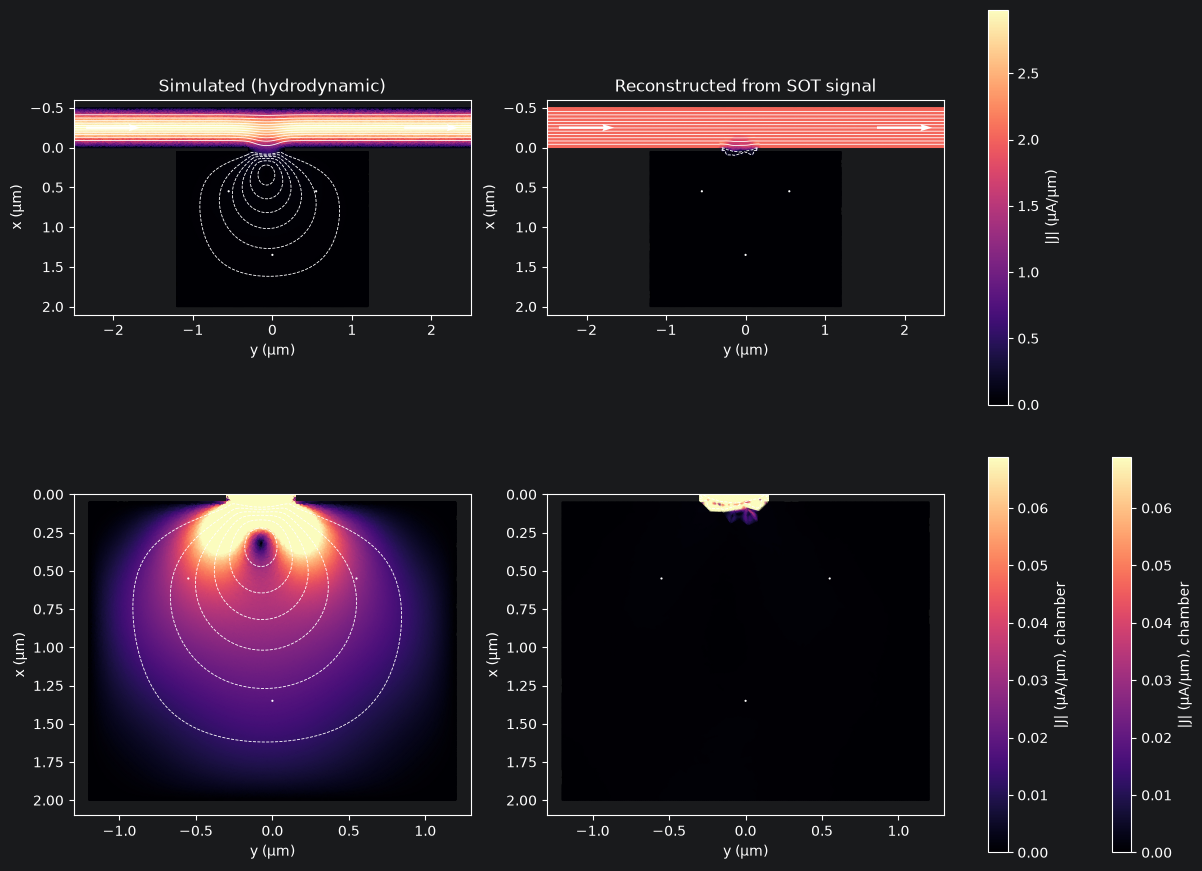

In [13]:
import matplotlib.tri as mtri

def refined_fields(m, g, subdiv=3):
    """Cubic-interpolated streamfunction and |J| on a refined triangulation.

    Plot frame: horizontal = y (vertices[:, 1]), vertical = x (vertices[:, 0]).
    """
    tri = mtri.Triangulation(m.vertices[:, 1], m.vertices[:, 0], m.triangles)
    interp = mtri.CubicTriInterpolator(tri, g, kind="geom")
    tri_f, g_f = mtri.UniformTriRefiner(tri).refine_field(g, triinterpolator=interp, subdiv=subdiv)
    dg_du, dg_dw = interp.gradient(tri_f.x, tri_f.y)
    J_abs_f = np.hypot(np.asarray(dg_du), np.asarray(dg_dw))
    return interp, tri_f, g_f, J_abs_f

# Streamline levels: channel spacing from the total current, vortex spacing from the
# simulated circulating current (same levels in both panels, so they compare directly)
g_true = res["streamfunction"]
I_tot = float(g_true.max())
in_chamber = constrictionmesh.vertices[:, 0] > 0.05
Gamma = float(-g_true[in_chamber].min())             # vortex has g < 0
levels_channel = np.linspace(0, I_tot, 13)[1:-1]
levels_vortex = np.linspace(-Gamma, 0, 7)[:-1] + Gamma / 12   # 6 nested loops
print(f"I = {I_tot:.3f} uA, Gamma = {Gamma:.4f} uA ({100 * Gamma / I_tot:.1f} % of I)")

cases = {
    "Simulated (hydrodynamic)": refined_fields(constrictionmesh, g_true),
    "Reconstructed from SOT signal": refined_fields(coarsemesh, g_c),
}

# Arrow positions (y, x) in the chamber and channel, to show the flow direction
arrow_pts = np.array([[0.0, 1.35], [0.55, 0.55], [-0.55, 0.55], [-2.0, -0.25], [2.0, -0.25]])

def chamber_vmax(tri_f, J_abs_f):
    sel = tri_f.y > 0.4   # chamber interior, away from the aperture inflow
    return float(np.nanmax(J_abs_f[sel]))

vmax_full = max(np.nanmax(c[3]) for c in cases.values())
vmax_cham = max(chamber_vmax(c[1], c[3]) for c in cases.values())

fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
for col, (title, (interp, tri_f, g_f, J_abs_f)) in enumerate(cases.items()):
    for row, (xlim, ylim, vmax) in enumerate([
        ((-2.5, 2.5), (2.1, -0.6), vmax_full),     # full view, x pointing down
        ((-1.3, 1.3), (2.1, 0.0), vmax_cham),      # chamber zoom
    ]):
        ax = axes[row, col]
        pc = ax.tripcolor(tri_f, J_abs_f, shading="gouraud", cmap="magma",
                          vmin=0, vmax=vmax, rasterized=True)
        ax.tricontour(tri_f, g_f, levels=levels_channel, colors="white", linewidths=0.6)
        ax.tricontour(tri_f, g_f, levels=levels_vortex, colors="white", linewidths=0.6)
        # Direction arrows from the interpolated current: Jy = -dg/dx, Jx = dg/dy
        dg_du, dg_dw = interp.gradient(arrow_pts[:, 0], arrow_pts[:, 1])
        ax.quiver(arrow_pts[:, 0], arrow_pts[:, 1], -dg_dw, dg_du, color="white",
                  angles="xy", pivot="mid", scale_units="inches", scale=None, width=0.006)
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal")
        ax.set_xlabel("y (µm)")
        ax.set_ylabel("x (µm)")
        if row == 0:
            ax.set_title(title)
    fig.colorbar(pc, ax=axes[row, :], shrink=0.9,
                 label="|J| (µA/µm)" + (", chamber" if row == 1 else ""))
fig.colorbar(axes[0, 0].collections[0], ax=axes[0, :], shrink=0.9, label="|J| (µA/µm)")
fig.savefig("vortex_reconstruction.pdf", dpi=300)
plt.show()

SNR = 6000: noise rms = 6.655e-07, noise floor sigma^2 = 4.429e-13
fine mesh: 38721 nodes, coarse mesh: 2201 nodes
warm start: a = 1.0125 uA, misfit = 2.553e-08;  lam3 = 5.428e-18, lam2 = 1.0e-11
outer  0:   205 evals, loss = 9.0571e-10  (5 s)
outer  1:   410 evals, loss = 9.0270e-10  (7 s)
outer  2:   445 evals, loss = 9.0267e-10  (7 s)
outer  3:   452 evals, loss = 9.0267e-10  (7 s)

                          fid    lam3*R3    lam2*TV      total
truth (on coarse)   6.468e-10  2.553e-12  9.247e-10  1.574e-09
warm start          2.553e-08  2.472e-23  4.561e-11  2.558e-08
fit                 1.617e-10  1.643e-12  7.394e-10  9.027e-10
noise floor         4.429e-13   (fit fid ~ this: well balanced; << : fitting noise)

residual rms vs noisy data = 1.271e-05, vs clean data = 1.270e-05, noise rms = 6.655e-07
Gamma: truth 0.0335 uA, fit 0.0310 uA


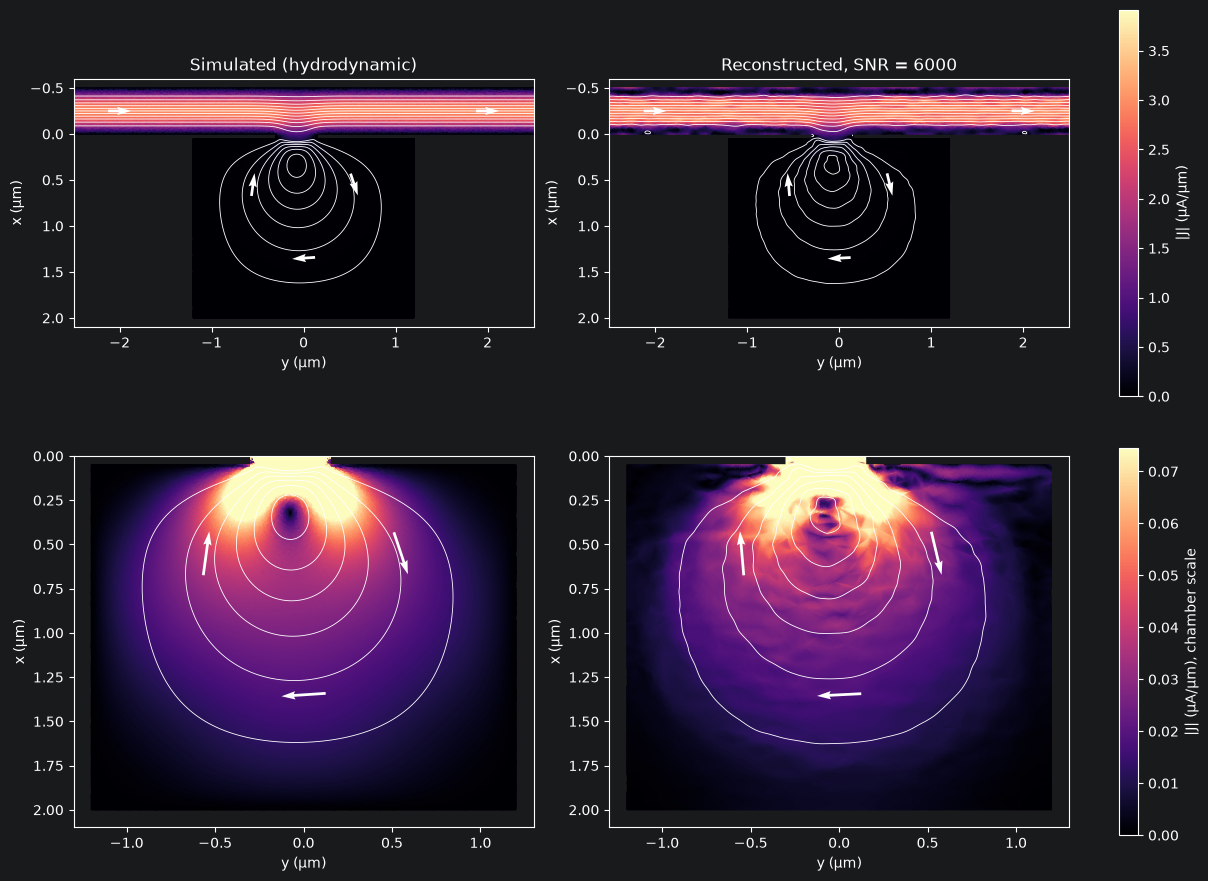

Streamlines: channel Δg = I/12 = 0.083 µA; vortex Δg = Γ/6 = 0.0058 µA


In [17]:
import time
import types
import torch
import matplotlib.tri as mtri
import scipy.interpolate

# ===========================================================================
# Settings
# ===========================================================================
SNR = 6000                     # signal peak-to-peak / rms noise
NOISE_SEED = 0
COARSE_MAX_AREA = 5e-3        # reconstruction mesh, h ~ 0.1 um
COARSE_REFINE = 0.05
LAM2 = 1e-11                  # TV on J
R3_FRACTION = 1e-4            # lam3 chosen so that lam3*R3(truth) = R3_FRACTION * (warm-start misfit)
N_OUTER = 15                  # L-BFGS outer steps (each up to 200 iterations)

fine = constrictionmesh
g_true_fine = res["streamfunction"]

# ===========================================================================
# 0. Noisy data (signal itself stays untouched)
# ===========================================================================
rng = np.random.default_rng(NOISE_SEED)
sigma = float(np.ptp(signal)) / SNR
data_noisy = (signal + rng.normal(0.0, sigma, size=signal.shape)).astype(signal.dtype)
print(f"SNR = {SNR}: noise rms = {sigma:.3e}, noise floor sigma^2 = {sigma**2:.3e}")

# ===========================================================================
# 1. Coarse reconstruction mesh, and the truth projected onto it
# ===========================================================================
coarse = mesh.SimplyConnectedCurrentMesh(
    vertices, segments, segment_markers, max_area=COARSE_MAX_AREA, refine_distance=COARSE_REFINE
)
m2g_c = forward.MeshToGrid(coarse, params)
fi, di = coarse.free_idx, coarse.dirichlet_idx
print(f"fine mesh: {fine.vertices.shape[0]} nodes, coarse mesh: {coarse.vertices.shape[0]} nodes")

fine_tri = mtri.Triangulation(fine.vertices[:, 0], fine.vertices[:, 1], fine.triangles)
g_true_c = np.ma.filled(
    mtri.LinearTriInterpolator(fine_tri, g_true_fine)(coarse.vertices[:, 0], coarse.vertices[:, 1]),
    np.nan,
)
missing = np.isnan(g_true_c)   # points the trifinder misses exactly on the boundary
if missing.any():
    g_true_c[missing] = scipy.interpolate.griddata(
        fine.vertices, g_true_fine, coarse.vertices[missing], method="nearest"
    )
I_tot = float(g_true_fine.max())
g_true_c[coarse.dirichletleft_mask] = 0.0
g_true_c[coarse.dirichletright_mask] = I_tot

# ===========================================================================
# 2. Ohmic warm start: best-fitting amplitude of the 1 uA ohmic flow
# ===========================================================================
Kc = coarse.stiffness_matrix
g1 = np.zeros(coarse.vertices.shape[0])
g1[coarse.dirichletright_mask] = 1.0
g1[fi] = coarse.stiffness_matrix_solver.solve(-Kc[fi][:, di] @ g1[di])
S1 = fwd.forward(*m2g_c.streamfunction_to_currents(g1))
a = float(np.sum(S1 * data_noisy) / np.sum(S1 * S1))
warm_misfit = float(np.mean((data_noisy - a * S1) ** 2))

# ===========================================================================
# 3. Regularizer R3 = int |grad omega|^2 dA (third-order Tikhonov on g)
#    omega_F = M_L^{-1} K_F g on free nodes (lumped mass); R3 = omega_F^T K_FF omega_F
# ===========================================================================
def to_torch_sparse(A):
    coo = A.tocoo()
    return torch.sparse_coo_tensor(
        torch.from_numpy(np.vstack([coo.row, coo.col]).astype(np.int64)),
        torch.from_numpy(coo.data).to(torch.float32),
        size=coo.shape,
    ).coalesce()

M_FF = coarse.mass_matrix[fi][:, fi]
inv_m = torch.from_numpy(1.0 / np.asarray(M_FF.sum(axis=1)).ravel()).to(torch.float32)
K_F = to_torch_sparse(Kc[fi])
K_FF = to_torch_sparse(Kc[fi][:, fi])

def R3(streamvector):
    omega_F = inv_m * (K_F @ streamvector)
    return torch.dot(omega_F, K_FF @ omega_F)

R3_truth = R3(torch.from_numpy(g_true_c).to(torch.float32)).item()
LAM3 = R3_FRACTION * warm_misfit / R3_truth
print(f"warm start: a = {a:.4f} uA, misfit = {warm_misfit:.3e};  lam3 = {LAM3:.3e}, lam2 = {LAM2:.1e}")

# ===========================================================================
# 4. Inverter on the noisy data: Tikhonov slot replaced by R3
# ===========================================================================
inv = backward.Inverter2D(m2g_c, fwd, data_noisy, lam1=LAM3, lam2=LAM2, lumped_mass=True)
inv._tikhonov_regularization = types.MethodType(lambda self, s: R3(s), inv)
with torch.no_grad():
    inv._solution[0] = a
    inv._solution[1:] = torch.from_numpy(a * g1[fi]).to(inv._solution.dtype)

# ===========================================================================
# 5. L-BFGS
# ===========================================================================
scale = float(np.mean(data_noisy ** 2))
opt = torch.optim.LBFGS([inv._solution], lr=1.0, max_iter=200, history_size=50,
                        tolerance_grad=1e-12, tolerance_change=1e-14,
                        line_search_fn="strong_wolfe")
loss_hist = []
def closure():
    opt.zero_grad()
    loss, *_ = inv._objective(inv._solution)
    (loss / scale).backward()
    loss_hist.append(loss.item())
    return loss / scale

t0, prev = time.time(), np.inf
for outer in range(N_OUTER):
    opt.step(closure)
    print(f"outer {outer:2d}: {len(loss_hist):5d} evals, loss = {loss_hist[-1]:.4e}  "
          f"({time.time() - t0:.0f} s)")
    if abs(prev - loss_hist[-1]) < 1e-6 * abs(loss_hist[-1]):
        break
    prev = loss_hist[-1]
g_fit = inv._solution_to_streamvector().detach().cpu().numpy()

# ===========================================================================
# 6. Diagnostics
# ===========================================================================
def terms(g):
    saved = inv._solution.detach().clone()
    with torch.no_grad():
        inv._solution[0] = float(g[coarse.dirichletright_mask][0])
        inv._solution[1:] = torch.from_numpy(g[fi]).to(inv._solution.dtype)
        _, fid, r3, tv = inv._objective(inv._solution)
        inv._solution.copy_(saved)
    return fid.item(), LAM3 * r3.item(), LAM2 * tv.item()

def chamber_gamma(m, g):
    return float(np.max(np.abs(g[m.vertices[:, 0] > 0.4])))

print(f"\n{'':18s} {'fid':>10s} {'lam3*R3':>10s} {'lam2*TV':>10s} {'total':>10s}")
for label, g in [("truth (on coarse)", g_true_c), ("warm start", a * g1), ("fit", g_fit)]:
    f, r, t = terms(g)
    print(f"{label:18s} {f:10.3e} {r:10.3e} {t:10.3e} {f + r + t:10.3e}")
print(f"{'noise floor':18s} {sigma**2:10.3e}   (fit fid ~ this: well balanced; << : fitting noise)")

pred = fwd.forward(*m2g_c.streamfunction_to_currents(g_fit))
print(f"\nresidual rms vs noisy data = {np.sqrt(np.mean((data_noisy - pred) ** 2)):.3e}, "
      f"vs clean data = {np.sqrt(np.mean((signal - pred) ** 2)):.3e}, noise rms = {sigma:.3e}")
print(f"Gamma: truth {chamber_gamma(fine, g_true_fine):.4f} uA, "
      f"fit {chamber_gamma(coarse, g_fit):.4f} uA")

# ===========================================================================
# 7. Thesis plot: streamlines as contours of g, |J| from a C1 cubic interpolant
#    Plot frame: horizontal = y (index 1), vertical = x (index 0, pointing down)
# ===========================================================================
def refined(m, g, kind):
    tri = mtri.Triangulation(m.vertices[:, 1], m.vertices[:, 0], m.triangles)
    interp = mtri.CubicTriInterpolator(tri, g, kind=kind)
    tri_f, g_f = mtri.UniformTriRefiner(tri).refine_field(g, triinterpolator=interp, subdiv=3)
    du, dw = interp.gradient(tri_f.x, tri_f.y)
    return interp, tri_f, g_f, np.hypot(np.asarray(du), np.asarray(dw))

cases = {
    "Simulated (hydrodynamic)": refined(fine, g_true_fine, "geom"),
    f"Reconstructed, SNR = {SNR}": refined(coarse, g_fit, "min_E"),
}
Gamma = float(-g_true_fine[fine.vertices[:, 0] > 0.05].min())
levels_channel = np.linspace(0, I_tot, 13)[1:-1]
levels_vortex = np.linspace(-Gamma, 0, 7)[:-1] + Gamma / 12

arrow_pts = np.array([[0.0, 1.35], [0.55, 0.55], [-0.55, 0.55], [-2.0, -0.25], [2.0, -0.25]])
ARROW_LEN = 0.25   # um

def vmax_region(tri_f, J, chamber):
    sel = tri_f.y > 0.4 if chamber else np.ones_like(tri_f.y, dtype=bool)
    return float(np.nanmax(J[sel]))

views = [((-2.5, 2.5), (2.1, -0.6), False), ((-1.3, 1.3), (2.1, 0.0), True)]
fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
for row, (xlim, ylim, chamber) in enumerate(views):
    vmax = max(vmax_region(c[1], c[3], chamber) for c in cases.values())
    for col, (title, (interp, tri_f, g_f, J_abs)) in enumerate(cases.items()):
        ax = axes[row, col]
        pc = ax.tripcolor(tri_f, J_abs, shading="gouraud", cmap="magma",
                          vmin=0, vmax=vmax, rasterized=True)
        for lv in (levels_channel, levels_vortex):
            ax.tricontour(tri_f, g_f, levels=lv, colors="white", linewidths=0.6,
                          negative_linestyles="solid")
        du, dw = interp.gradient(arrow_pts[:, 0], arrow_pts[:, 1])
        vh, vv = -np.asarray(dw), np.asarray(du)          # (Jy, Jx) in plot frame
        norm = np.hypot(vh, vv)
        ax.quiver(arrow_pts[:, 0], arrow_pts[:, 1], vh / norm, vv / norm, color="white",
                  angles="xy", scale_units="xy", scale=1 / ARROW_LEN, pivot="mid", width=0.006)
        ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.set_aspect("equal")
        ax.set_xlabel("y (µm)"); ax.set_ylabel("x (µm)")
        if row == 0:
            ax.set_title(title)
    fig.colorbar(pc, ax=axes[row, :], shrink=0.9,
                 label="|J| (µA/µm)" + (", chamber scale" if chamber else ""))
fig.savefig(f"vortex_reconstruction_SNR{SNR}.pdf", dpi=300)
plt.show()
print(f"Streamlines: channel Δg = I/12 = {I_tot / 12:.3f} µA; vortex Δg = Γ/6 = {Gamma / 6:.4f} µA")